In [45]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, chi2, f_classif, mutual_info_classif
from sklearn.linear_model import Perceptron, LogisticRegression, SGDClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, PowerTransformer

from src.auxiliares import dataframe_coeficientes
from src.config import DADOS_LIMPOS
from src.graficos import plot_coeficientes, plot_comparar_metricas_modelos
from src.models import RANDOM_STATE
from src.models import (
    grid_search_cv_classificador,
    treinar_e_validar_modelo_classificacao,
    organiza_resultados
)

sns.set_theme(palette='bright')

In [10]:
df = pd.read_parquet(DADOS_LIMPOS)
df.head()

,area_mean,area_se,area_worst,compactness_mean,compactness_se,compactness_worst,concave points_mean,concave points_se,concave points_worst,concavity_mean,...,radius_worst,smoothness_mean,smoothness_se,smoothness_worst,symmetry_mean,symmetry_se,symmetry_worst,texture_mean,texture_se,texture_worst
0,1001.0,153.40,2019.0,0.27760,0.04904,0.6656,0.14710,0.01587,0.2654,0.3001,...,25.38,0.11840,0.006399,0.1622,0.2419,0.03003,0.4601,10.38,0.9053,17.33
1,1326.0,74.08,1956.0,0.07864,0.01308,0.1866,0.07017,0.01340,0.1860,0.0869,...,24.99,0.08474,0.005225,0.1238,0.1812,0.01389,0.2750,17.77,0.7339,23.41
2,1203.0,94.03,1709.0,0.15990,0.04006,0.4245,0.12790,0.02058,0.2430,0.1974,...,23.57,0.10960,0.006150,0.1444,0.2069,0.02250,0.3613,21.25,0.7869,25.53
3,386.1,27.23,567.7,0.28390,0.07458,0.8663,0.10520,0.01867,0.2575,0.2414,...,14.91,0.14250,0.009110,0.2098,0.2597,0.05963,0.6638,20.38,1.1560,26.50
4,1297.0,94.44,1575.0,0.13280,0.02461,0.2050,0.10430,0.01885,0.1625,0.1980,...,22.54,0.10030,0.011490,0.1374,0.1809,0.01756,0.2364,14.34,0.7813,16.67


In [11]:
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

In [12]:
le = LabelEncoder()

y =le.fit_transform(y)

y[:20]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0])

In [13]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [61]:
preprocessamento = Pipeline(
    steps=[('scaler', PowerTransformer()), 
           ('selector', SelectKBest(mutual_info_classif, k=15))
        ]

)

In [62]:
classificadores = {
   'DummyClassifier': {
       'preprocessor': None,
       'classificador': DummyClassifier(strategy='stratified')
   },

    'Perceptron': {
           'preprocessor': None,
           'classificador': Perceptron()
       },

   'LogisticRegression': {
          'preprocessor': None,
          'classificador': LogisticRegression()
      },

    'SGDClassifier': {
           'preprocessor': None,
           'classificador': SGDClassifier()
       }                                                    
}

In [63]:
resultados = {
    nome_modelo: treinar_e_validar_modelo_classificacao(X, y, kf, **classificador)
    for nome_modelo, classificador in classificadores.items()
}

df_resultados = organiza_resultados(resultados)

df_resultados

c:\Users\paulo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\paulo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://sciki

,model,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1,test_precision,test_recall,test_roc_auc,test_average_precision,time_seconds
0,DummyClassifier,0.066681,0.044208,0.535088,0.512119,0.404494,0.391304,0.418605,0.537504,0.396584,0.110889
1,DummyClassifier,0.0,0.008385,0.54386,0.519161,0.409091,0.4,0.418605,0.547003,0.402285,0.008385
2,DummyClassifier,0.000996,0.008533,0.482456,0.46627,0.365591,0.333333,0.404762,0.517857,0.377167,0.009529
3,DummyClassifier,0.000997,0.006976,0.5,0.480159,0.373626,0.346939,0.404762,0.590278,0.422847,0.007973
4,DummyClassifier,0.002045,0.007974,0.575221,0.545272,0.428571,0.428571,0.428571,0.519282,0.381261,0.010019
5,Perceptron,0.026804,0.012686,0.885965,0.876351,0.847059,0.857143,0.837209,0.930233,0.936629,0.03949
6,Perceptron,0.0,0.017528,0.877193,0.837209,0.805556,1.0,0.674419,0.925647,0.926298,0.017528
7,Perceptron,0.00299,0.00897,0.894737,0.881944,0.853659,0.875,0.833333,0.964286,0.948694,0.011959
8,Perceptron,0.00299,0.012956,0.95614,0.940476,0.936709,1.0,0.880952,0.993386,0.990119,0.015946
9,Perceptron,0.00299,0.012053,0.849558,0.875419,0.828283,0.719298,0.97619,0.982227,0.977338,0.015044


In [64]:
df_resultados.groupby('model').mean().sort_values(by='test_recall')

,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1,test_precision,test_recall,test_roc_auc,test_average_precision,time_seconds
model,,,,,,,,,,
DummyClassifier,0.014144,0.015215,0.527325,0.504596,0.396275,0.38003,0.415061,0.542385,0.396029,0.029359
Perceptron,0.007155,0.012839,0.892719,0.88228,0.854253,0.890288,0.840421,0.959156,0.955816,0.019993
SGDClassifier,0.004018,0.011588,0.845024,0.855407,0.824556,0.794716,0.896456,0.972933,0.964797,0.015606
LogisticRegression,0.022366,0.01033,0.945567,0.937595,0.925102,0.947054,0.90598,0.989801,0.985937,0.032696


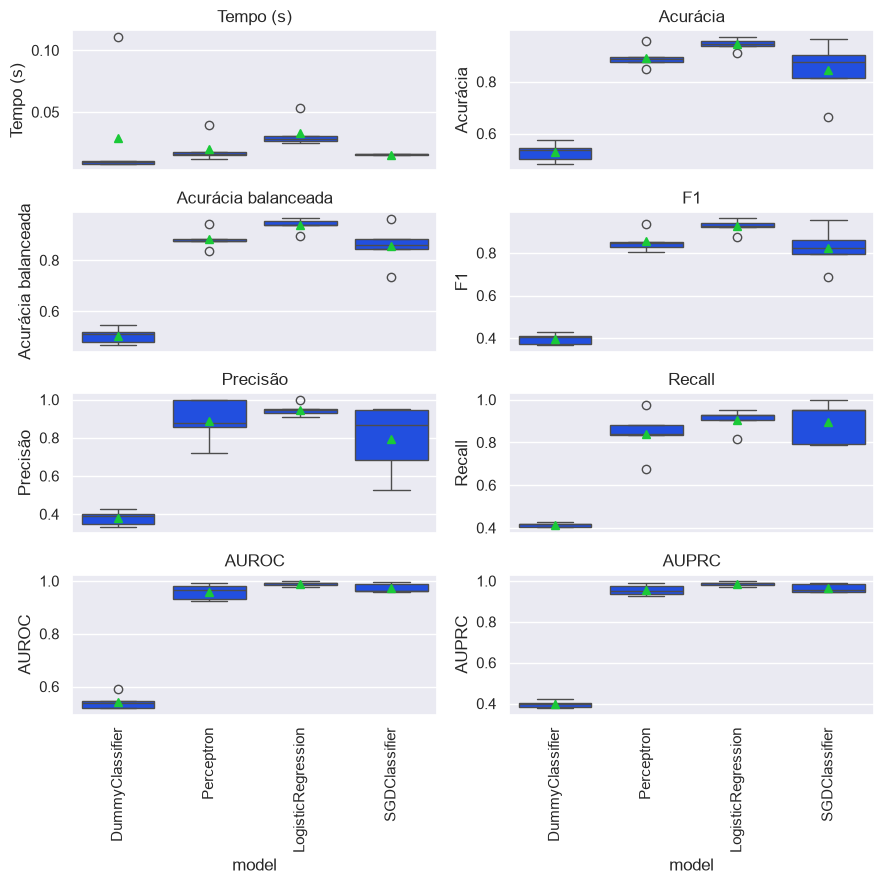

In [65]:
plot_comparar_metricas_modelos(df_resultados)

In [66]:
param_grid = {
    'clf__C': [0.1, 1, 10, 100],
    'clf__penalty': ['l1', 'l2','elasticnet', None],
    'clf__class_weight': [None, 'balanced'],
    'clf__l1_ratio': [0.1, 0.25, 0.5, 0.75, 0.9]
}

In [67]:
clf = LogisticRegression(solver='saga', random_state=RANDOM_STATE)

grid_search = grid_search_cv_classificador(
    clf, param_grid, kf, preprocessamento, refit_metric='recall'
)

grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ver='saga'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__C': [0.1, 1, ...], 'clf__class_weight': [None, 'balanced'], 'clf__l1_ratio': [0.1, 0.25, ...], 'clf__penalty': ['l1', 'l2', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['accuracy', 'balanced_accuracy', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default val

In [68]:
grid_search.fit(X, y)

Fitting 5 folds for each of 160 candidates, totalling 800 fits


c:\Users\paulo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\paulo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1399: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\paulo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l2 with l1_ratio=0.1. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\paulo\AppData\Local\Progra

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ver='saga'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__C': [0.1, 1, ...], 'clf__class_weight': [None, 'balanced'], 'clf__l1_ratio': [0.1, 0.25, ...], 'clf__penalty': ['l1', 'l2', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['accuracy', 'balanced_accuracy', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default val

In [69]:
grid_search.best_params_

{'clf__C': 1,
 'clf__class_weight': 'balanced',
 'clf__l1_ratio': 0.1,
 'clf__penalty': 'l2'}

In [70]:
grid_search.best_score_

np.float64(0.9527131782945737)

In [71]:
grid_search.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['area_mean','area_se','area_worst',...,'texture_mean','texture_se', 'texture_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('selector', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be i

In [72]:
grid_search.best_estimator_['preprocessor'].get_feature_names_out()

array(['area_mean', 'area_se', 'area_worst', 'compactness_mean',
       'compactness_worst', 'concave points_mean', 'concave points_worst',
       'concavity_mean', 'concavity_worst', 'perimeter_mean',
       'perimeter_se', 'perimeter_worst', 'radius_mean', 'radius_se',
       'radius_worst'], dtype=object)

In [73]:
grid_search.best_estimator_['clf'].coef_

array([[-0.32498429,  1.18476726,  1.42458285, -1.4449298 ,  0.2808844 ,
         1.32090235,  1.53174115,  0.04005867,  1.22411141, -0.41532769,
        -0.37079041,  0.92070109, -0.4775338 ,  0.54755453,  1.22321311]])

In [74]:
coefs = dataframe_coeficientes(
    grid_search.best_estimator_['clf'].coef_[0],
    grid_search.best_estimator_['preprocessor'].get_feature_names_out()
)

coefs

,coeficiente
compactness_mean,-1.444930
radius_mean,-0.477534
perimeter_mean,-0.415328
perimeter_se,-0.370790
area_mean,-0.324984
concavity_mean,0.040059
compactness_worst,0.280884
radius_se,0.547555
perimeter_worst,0.920701
area_se,1.184767


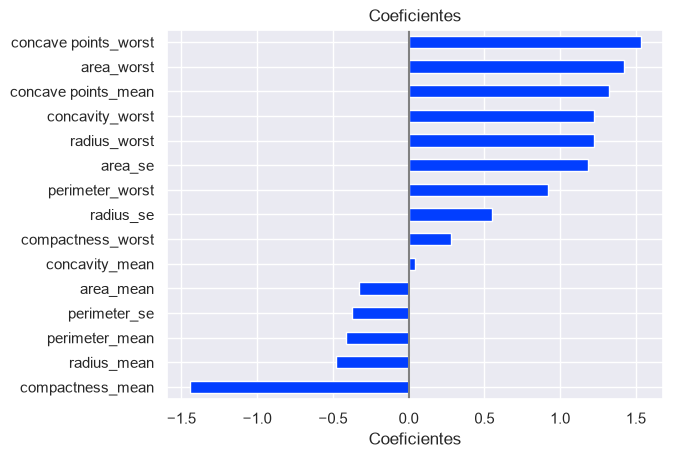

In [75]:
plot_coeficientes(coefs)

Os coeficientes $w_i$ em uma regressão logística não são interpretados diretamente como em uma regressão linear. Em vez disso, eles representam o **logaritmo do odds ratio** associado a cada variável.

- **Odds (Chances):** Razão entre a probabilidade do evento ocorrer e a probabilidade de não ocorrer.

  $$
  \text{Odds} = \frac{\text{Probabilidade do Evento}}{1 - \text{Probabilidade do Evento}}
  $$

- **Odds Ratio:** Medida de quanto as chances mudam com uma unidade de aumento na variável independente.

- **Coeficiente ($w_i$):** Representa a mudança nos **log-odds** do resultado por unidade de aumento na variável $X_i$.

  $$
  \text{Log-Odds} = w_0 + w_1X_1 + w_2X_2 + \dots + w_nX_n
  $$

Para interpretar os coeficientes em termos mais intuitivos, podemos calcular o **exponencial do coeficiente**:

$$
\text{Odds Ratio} = e^{w_i}
$$

- **Interpretação do Odds Ratio:**
  - **Valor > 1:** Aumenta as chances do evento ocorrer.
  - **Valor = 1:** Não afeta as chances.
  - **Valor < 1:** Diminui as chances do evento ocorrer.


Imagine que estamos modelando a probabilidade de um paciente ter uma doença com base na idade e no hábito de fumar.

$$
\text{Log-Odds} = w_0 + w_1 (\text{Idade}) + w_2 (\text{Fumante})
$$

Suponha que obtivemos os seguintes coeficientes:

- $w_0 = -2$
- $w_1 = 0{,}05$
- $w_2 = 1{,}5$

1. **Coeficiente da Idade ($w_1 = 0{,}05$):**

   - **Log-Odds:** Para cada aumento de 1 ano na idade, o log-odds de ter a doença aumenta em 0,05.
   - **Odds Ratio:** $e^{0{,}05} \approx 1{,}051$
   - **Interpretação:** Cada ano adicional de idade aumenta as chances de ter a doença em aproximadamente **5,1%**.

2. **Coeficiente do Fumante ($w_2 = 1{,}5$):**

   - **Log-Odds:** Se o paciente é fumante (1), o log-odds de ter a doença aumenta em 1,5 em comparação com não fumantes (0).
   - **Odds Ratio:** $e^{1{,}5} \approx 4{,}48$
   - **Interpretação:** Fumantes têm **4,48 vezes** mais chances de ter a doença do que não fumantes.


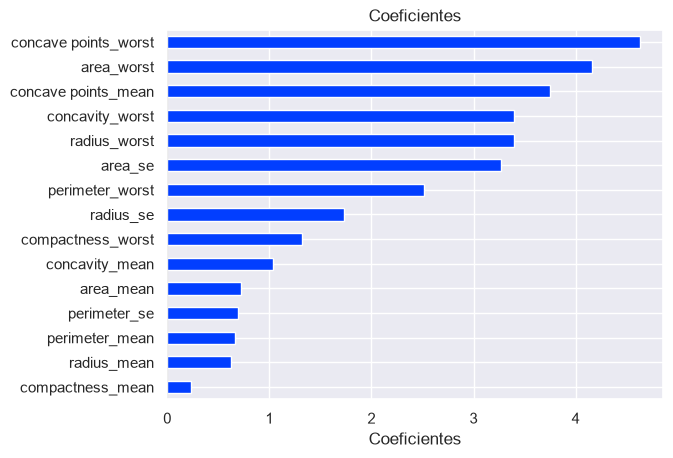

In [76]:
coefs_odds = coefs.copy()
coefs_odds['coeficiente'] = np.exp(coefs_odds['coeficiente'])

plot_coeficientes(coefs_odds)

In [77]:
coefs_odds.sort_values(by='coeficiente', ascending=False)

,coeficiente
concave points_worst,4.626225
area_worst,4.156124
concave points_mean,3.746801
concavity_worst,3.401143
radius_worst,3.398089
area_se,3.269926
perimeter_worst,2.511050
radius_se,1.729020
compactness_worst,1.324301
concavity_mean,1.040872


Em machine learning, trabalhamos frequentemente com conjuntos de dados que possuem um grande número de variáveis, também chamadas de *features* ou atributos. Embora possa parecer vantajoso utilizar o máximo de informações possível ao treinar um modelo, na prática, nem todas as variáveis contribuem de forma significativa para a performance do modelo. Algumas podem até introduzir ruído ou redundância, prejudicando a capacidade de generalização.

A seleção de variáveis, ou *feature selection*, é o processo de identificar e selecionar um subconjunto relevante de variáveis para utilizar na construção de um modelo preditivo. O objetivo é melhorar a performance do modelo, reduzir o tempo de treinamento e facilitar a interpretação dos resultados.

1. **Redução de Dimensionalidade**: Trabalhar com menos variáveis diminui a complexidade do modelo, o que pode levar a melhores resultados, especialmente em conjuntos de dados com muitas dimensões (o chamado "problema da maldição da dimensionalidade").

2. **Melhora na Performance**: Removendo variáveis irrelevantes ou redundantes, o modelo pode focar nas informações mais importantes, o que geralmente melhora a precisão e a capacidade de generalização.

3. **Redução de *Overfitting***: Modelos treinados com muitas variáveis irrelevantes têm maior chance de se ajustar ao ruído dos dados de treinamento, o que prejudica a performance em dados não vistos.

4. **Interpretação Simplificada**: Com menos variáveis, é mais fácil entender e interpretar como o modelo toma decisões, o que é crucial em muitas aplicações práticas.

Existem diversas técnicas para realizar a seleção de variáveis, que podem ser categorizadas em três grupos principais:

1. **Métodos *Filter* (Filtro)**: Baseiam-se em características estatísticas das variáveis, sem considerar nenhum algoritmo de aprendizado específico. Exemplos incluem o uso de correlação, teste de qui-quadrado e informação mútua.

2. **Métodos *Wrapper* (Envoltório)**: Utilizam um algoritmo de aprendizado para avaliar a performance de diferentes subconjuntos de variáveis. Apesar de serem mais precisos, são computacionalmente mais custosos. Exemplos incluem a busca exaustiva, seleção sequencial e eliminação recursiva de variáveis (*Recursive Feature Elimination*).

3. **Métodos *Embedded* (Embutidos)**: Realizam a seleção de variáveis durante o processo de treinamento do modelo. Alguns algoritmos têm essa capacidade intrínseca, como árvores de decisão e modelos com regularização (como Lasso e Ridge Regression).


In [46]:
selector_chi2 = SelectKBest(score_func=chi2, k=15)

X_chi2 = selector_chi2.fit_transform(X, y)

X_chi2.shape

(569, 15)

In [47]:
X_chi2[:5]

array([[1.001e+03, 1.534e+02, 2.019e+03, 6.656e-01, 2.654e-01, 3.001e-01,
        7.119e-01, 1.228e+02, 8.589e+00, 1.846e+02, 1.799e+01, 1.095e+00,
        2.538e+01, 1.038e+01, 1.733e+01],
       [1.326e+03, 7.408e+01, 1.956e+03, 1.866e-01, 1.860e-01, 8.690e-02,
        2.416e-01, 1.329e+02, 3.398e+00, 1.588e+02, 2.057e+01, 5.435e-01,
        2.499e+01, 1.777e+01, 2.341e+01],
       [1.203e+03, 9.403e+01, 1.709e+03, 4.245e-01, 2.430e-01, 1.974e-01,
        4.504e-01, 1.300e+02, 4.585e+00, 1.525e+02, 1.969e+01, 7.456e-01,
        2.357e+01, 2.125e+01, 2.553e+01],
       [3.861e+02, 2.723e+01, 5.677e+02, 8.663e-01, 2.575e-01, 2.414e-01,
        6.869e-01, 7.758e+01, 3.445e+00, 9.887e+01, 1.142e+01, 4.956e-01,
        1.491e+01, 2.038e+01, 2.650e+01],
       [1.297e+03, 9.444e+01, 1.575e+03, 2.050e-01, 1.625e-01, 1.980e-01,
        4.000e-01, 1.351e+02, 5.438e+00, 1.522e+02, 2.029e+01, 7.572e-01,
        2.254e+01, 1.434e+01, 1.667e+01]])

In [48]:
selector_chi2.get_feature_names_out(X.columns)

array(['area_mean', 'area_se', 'area_worst', 'compactness_worst',
       'concave points_worst', 'concavity_mean', 'concavity_worst',
       'perimeter_mean', 'perimeter_se', 'perimeter_worst', 'radius_mean',
       'radius_se', 'radius_worst', 'texture_mean', 'texture_worst'],
      dtype=object)

In [49]:
selector_chi2.scores_

array([5.39916559e+04, 8.75850471e+03, 1.12598432e+05, 5.40307549e+00,
       6.13785332e-01, 1.93149220e+01, 1.05440354e+01, 3.05231563e-01,
       1.34854195e+01, 1.97123536e+01, 1.04471761e+00, 3.95169151e+01,
       7.43065536e-05, 6.37136566e-03, 2.31522407e-01, 2.01110286e+03,
       2.50571896e+02, 3.66503542e+03, 2.66104917e+02, 3.46752472e+01,
       4.91689157e+02, 1.49899264e-01, 3.26620664e-03, 3.97365694e-01,
       2.57379775e-01, 8.03633831e-05, 1.29886140e+00, 9.38975081e+01,
       9.79353970e-03, 1.74449400e+02])

In [51]:
selector_chi2.pvalues_

array([0.00000000e+000, 0.00000000e+000, 0.00000000e+000, 2.01012999e-002,
       4.33366115e-001, 1.10836762e-005, 1.16563638e-003, 5.80621137e-001,
       2.40424384e-004, 9.00175712e-006, 3.06726812e-001, 3.25230064e-010,
       9.93122221e-001, 9.36379753e-001, 6.30397277e-001, 0.00000000e+000,
       1.94877489e-056, 0.00000000e+000, 8.01397628e-060, 3.89553429e-009,
       6.11324751e-109, 6.98631644e-001, 9.54425121e-001, 5.28452867e-001,
       6.11926026e-001, 9.92847410e-001, 2.54421307e-001, 3.32292194e-022,
       9.21168192e-001, 7.89668299e-040])

In [52]:
selector_f = SelectKBest(score_func=f_classif, k=15)

X_f = selector_f.fit_transform(X, y)

X_f.shape

(569, 15)

In [53]:
selector_f.get_feature_names_out()

array(['area_mean', 'area_se', 'area_worst', 'compactness_mean',
       'compactness_worst', 'concave points_mean', 'concave points_worst',
       'concavity_mean', 'concavity_worst', 'perimeter_mean',
       'perimeter_se', 'perimeter_worst', 'radius_mean', 'radius_se',
       'radius_worst'], dtype=object)

In [54]:
selector_f.scores_

array([5.73060747e+02, 2.43651586e+02, 6.61600206e+02, 3.13233079e+02,
       5.32473391e+01, 3.04341063e+02, 8.61676020e+02, 1.13262760e+02,
       9.64385393e+02, 5.33793126e+02, 3.90144816e+01, 4.36691939e+02,
       9.34592949e-02, 3.46827476e+00, 6.64439606e+01, 6.97235272e+02,
       2.53897392e+02, 8.97944219e+02, 6.46981021e+02, 2.68840327e+02,
       8.60781707e+02, 8.36511234e+01, 2.55796780e+00, 1.22472880e+02,
       6.95274435e+01, 2.41174067e-02, 1.18860232e+02, 1.18096059e+02,
       3.90947023e-02, 1.49596905e+02])

In [55]:
selector_f.pvalues_

array([4.73456431e-088, 5.89552139e-046, 2.82884770e-097, 3.93826311e-056,
       9.97599465e-013, 7.06981635e-055, 7.10115016e-116, 3.07230877e-024,
       1.96909971e-124, 9.96655576e-084, 8.26017617e-010, 2.46466396e-072,
       7.59936804e-001, 6.30735508e-002, 2.31643245e-015, 8.43625104e-101,
       1.65190518e-047, 5.77139714e-119, 8.46594057e-096, 9.73894866e-050,
       8.48229192e-116, 1.05185036e-018, 1.10296609e-001, 6.57514363e-026,
       5.73338403e-016, 8.76641818e-001, 2.95112058e-025, 4.05863605e-025,
       8.43332029e-001, 1.07805749e-030])

In [56]:
selector_mi = SelectKBest(score_func=mutual_info_classif, k=15)

X_mi = selector_mi.fit_transform(X, y)

X_mi.shape

(569, 15)

In [57]:
selector_mi.get_feature_names_out()

array(['area_mean', 'area_se', 'area_worst', 'compactness_mean',
       'compactness_worst', 'concave points_mean', 'concave points_worst',
       'concavity_mean', 'concavity_worst', 'perimeter_mean',
       'perimeter_se', 'perimeter_worst', 'radius_mean', 'radius_se',
       'radius_worst'], dtype=object)

In [58]:
selector_mi.scores_

array([0.36108783, 0.3404008 , 0.46320999, 0.21356402, 0.07703165,
       0.22479017, 0.43884864, 0.1281261 , 0.43801254, 0.37452688,
       0.11595714, 0.31548535, 0.00514004, 0.03894173, 0.06716673,
       0.40286423, 0.27551588, 0.47739004, 0.36635232, 0.25066703,
       0.45055051, 0.08182935, 0.01470076, 0.10121509, 0.07089583,
       0.01655699, 0.09366062, 0.09672033, 0.        , 0.12284349])

In [59]:
selector_f.pvalues_

array([4.73456431e-088, 5.89552139e-046, 2.82884770e-097, 3.93826311e-056,
       9.97599465e-013, 7.06981635e-055, 7.10115016e-116, 3.07230877e-024,
       1.96909971e-124, 9.96655576e-084, 8.26017617e-010, 2.46466396e-072,
       7.59936804e-001, 6.30735508e-002, 2.31643245e-015, 8.43625104e-101,
       1.65190518e-047, 5.77139714e-119, 8.46594057e-096, 9.73894866e-050,
       8.48229192e-116, 1.05185036e-018, 1.10296609e-001, 6.57514363e-026,
       5.73338403e-016, 8.76641818e-001, 2.95112058e-025, 4.05863605e-025,
       8.43332029e-001, 1.07805749e-030])

In [60]:
comparando_seletores = pd.DataFrame(
    {
    'chi2': selector_chi2.get_support(),
    'f_classif': selector_f.get_support(),
    'mi': selector_mi.get_support()
},
    index=X.columns
)

comparando_seletores

,chi2,f_classif,mi
area_mean,True,True,True
area_se,True,True,True
area_worst,True,True,True
compactness_mean,False,True,True
compactness_se,False,False,False
compactness_worst,True,True,True
concave points_mean,False,True,True
concave points_se,False,False,False
concave points_worst,True,True,True
concavity_mean,True,True,True
